# What are categorical plots?
Categorical plots help us compare values across groups, such as:
- Average tip by day.
- Number of customers by day.
- Bill distributions for smokers and non-smokers.
- Tips across lunch and dinner.

We'll continue using Seaborn's built-in tips dataset.

# Imports and Dataset

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

df = sns.load_dataset("tips")

df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


# First categorical plot: barplot()
A barplot() typically displays an aggregate statistic, by default the mean, for each category.

For example, let's compare the average tip for each day.

Before running the code, try predicting the output.

In [2]:

from IPython.display import HTML, display

html_code = """
<div id="barplot-quiz" style="font-family: Arial, sans-serif; max-width: 650px; margin: auto;">
    <h3>Seaborn Day 2 — Prediction Challenge</h3>
    <p><b>Question:</b> What will this code display?</p>

    <pre style="background:#f3f4f6; color:#111827; padding:12px; border-radius:6px; overflow-x:auto;">
sns.barplot(data=df, x="day", y="tip")
plt.show()
    </pre>

    <label style="display:block; margin:12px 0;">
        <input type="radio" name="barplot-answer" value="A">
        A. The total number of customers on each day
    </label>

    <label style="display:block; margin:12px 0;">
        <input type="radio" name="barplot-answer" value="B">
        B. The average tip for each day
    </label>

    <label style="display:block; margin:12px 0;">
        <input type="radio" name="barplot-answer" value="C">
        C. Every customer's tip as a separate bar
    </label>

    <p><b>Why did you choose your answer?</b></p>

    <label style="display:block; margin:10px 0;">
        <input type="radio" name="barplot-reason" value="mean">
        Because barplot() calculates the mean by default
    </label>

    <label style="display:block; margin:10px 0;">
        <input type="radio" name="barplot-reason" value="count">
        Because barplot() counts observations by default
    </label>

    <label style="display:block; margin:10px 0;">
        <input type="radio" name="barplot-reason" value="individual">
        Because every row becomes its own bar
    </label>

    <button type="button" onclick="checkBarplot()"
        style="background:#2563eb; color:white; padding:10px 18px;
        border:0; border-radius:6px; cursor:pointer; margin-top:10px;">
        Check Prediction
    </button>

    <button type="button" onclick="resetBarplot()"
        style="padding:10px 18px; margin-left:6px; border:1px solid #aaa;
        border-radius:6px; cursor:pointer;">
        Try Again
    </button>

    <p id="barplot-result" aria-live="polite"></p>
</div>

<script>
function checkBarplot() {
    const answer = document.querySelector(
        'input[name="barplot-answer"]:checked'
    );
    const reason = document.querySelector(
        'input[name="barplot-reason"]:checked'
    );
    const result = document.getElementById("barplot-result");

    if (!answer || !reason) {
        result.textContent = "Please answer both questions first.";
        result.style.color = "#b45309";
        return;
    }

    if (answer.value === "B" && reason.value === "mean") {
        result.innerHTML =
            "<b>Correct! 🎉</b><br>" +
            "barplot() calculates the mean tip for each day by default.";
        result.style.color = "#15803d";
    } else {
        result.innerHTML =
            "<b>Not quite!</b><br>" +
            "The correct answer is B, and the reason is that " +
            "barplot() calculates the mean by default.";
        result.style.color = "#dc2626";
    }
}

function resetBarplot() {
    document.querySelectorAll(
        'input[name="barplot-answer"], input[name="barplot-reason"]'
    ).forEach(input => input.checked = false);

    document.getElementById("barplot-result").textContent = "";
}
</script>
"""

display(HTML(html_code))


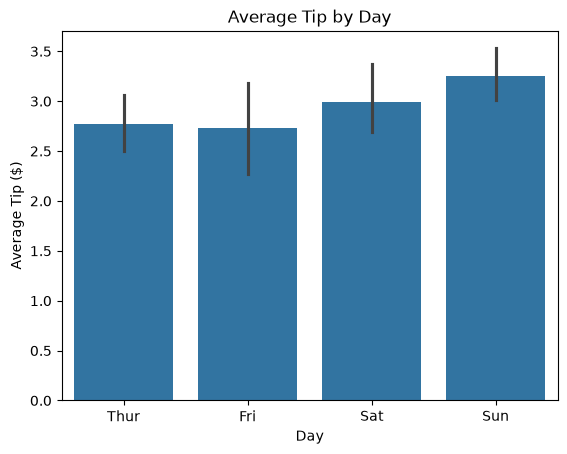

In [3]:
sns.barplot(data=df, x="day", y="tip")

plt.title("Average Tip by Day")
plt.xlabel("Day")
plt.ylabel("Average Tip ($)")

plt.show()

**Why?**\
In this code:
sns.barplot(data=df, x="day", y="tip")



- data=df uses the tips dataset.
- x="day" groups customers by day (Thur, Fri, Sat, Sun).
- y="tip" provides the numerical values to aggregate.
- By default, barplot() calculates the mean tip for each day.
For example, conceptually:
$$ \text{Mean tip}=\frac{\text{Sum of tips}}{\text{Number of observations}} $$

Each bar represents a day's average tip, not the total tip or the number of customers.

The vertical error bars show uncertainty around the estimated mean, using a bootstrap confidence interval by default.

# Next concept: countplot()
number of observations in each category.

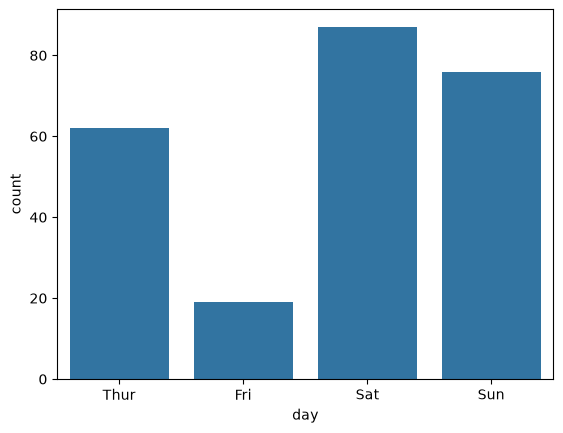

In [15]:
sns.countplot(data=df, x="day")

plt.show()

This plot shows number of customers for each day.

sns.countplot() counts how many rows belong to each category.

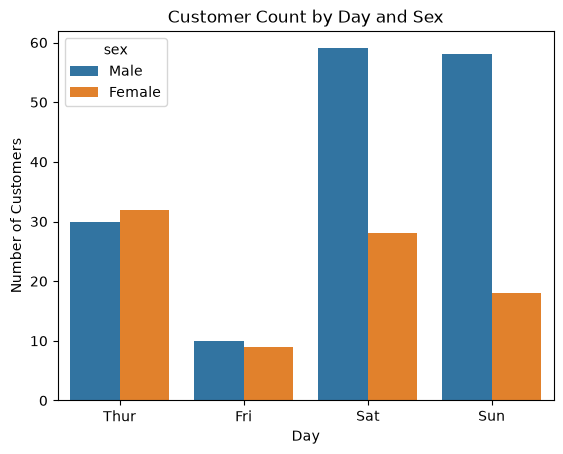

In [14]:
sns.countplot(data=df, x="day", hue="sex")

plt.title("Customer Count by Day and Sex")
plt.xlabel("Day")
plt.ylabel("Number of Customers")

plt.show()

- x="day" groups the customers by day.
- hue="sex" splits each day's count into separate groups by sex.
- The legend identifies the groups by color.

For example, Thursday will have separate bars for the two sex categories, showing their respective customer counts.

Remember the difference
| Function | What it shows |
| :--- | :--- |
| sns.barplot() | Average tip for each day, by default |
| sns.countplot() | Number of customers recorded for each day |

# Next concept: boxplot()
A box plot helps us understand the distribution of numerical data across categories, including the median, spread, and potential outliers.

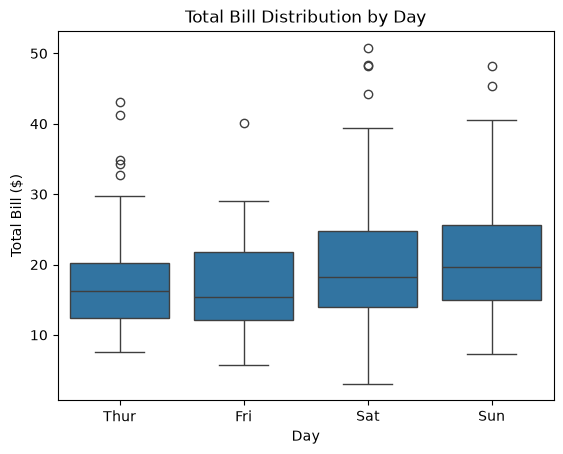

In [13]:
sns.boxplot(data=df, x="day", y="total_bill")

plt.title("Total Bill Distribution by Day")
plt.xlabel("Day")
plt.ylabel("Total Bill ($)")

plt.show()

This plot shows the distribution of total bills for each day, including medians and potential outliers.

## How to read a box plot

<div align="center">
	<img src="../Images/Seaborn_1.png" style="border-radius: 30px; max-width: 80%;">
</div>

- Line inside the box: median total bill.
- Bottom of the box: first quartile (Q1).
- Top of the box: third quartile (Q3).
- Box height: interquartile range (IQR), \(Q3-Q1\).
- Whiskers: extend to the most extreme values within the usual 1.5 × IQR rule.
- Individual points beyond whiskers: potential outliers.

Remember, potential outliers are not necessarily errors; they may be legitimate unusually large or small bills.

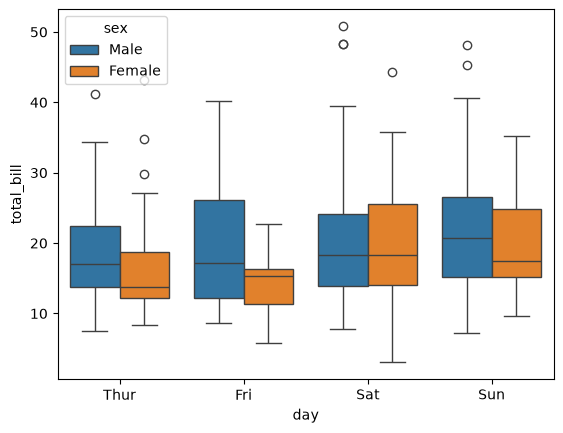

In [12]:
sns.boxplot(data=df, x="day", y="total_bill", hue="sex")

plt.show()

This plot shows total bill distributions for each day, separated by sex.

# Next concept: violinplot()
A violin plot shows the distribution's shape and density, in addition to its range and central tendency.

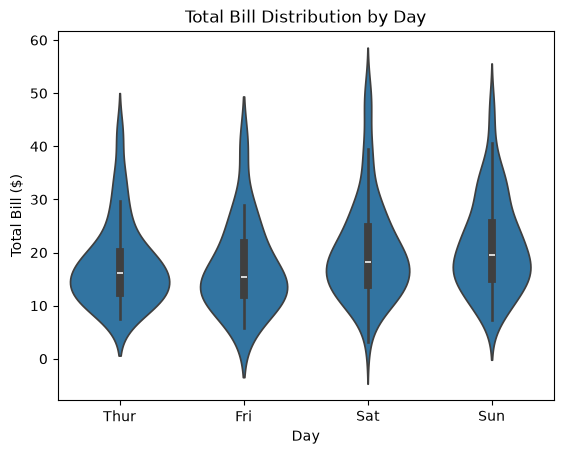

In [17]:
sns.violinplot(data=df, x="day", y="total_bill")

plt.title("Total Bill Distribution by Day")
plt.xlabel("Day")
plt.ylabel("Total Bill ($)")
plt.show()

This plot shows the distribution and density shape of total bills for each day.

* x="day" groups observations by day.
* y="total_bill" displays bill amounts.
* violinplot() visualizes the distribution's shape using a kernel density estimate (KDE).

## How to read a violin plot

<div align="center">
	<img src="../Images/Seaborn_2.png" style="border-radius: 30px; max-width: 80%;">
</div>

- Wider sections: more observations are concentrated around those values.
- Narrower sections: fewer observations are concentrated there.
- Vertical position: indicates the total bill amount.

Unlike a box plot, a violin plot reveals the shape of the distribution. It can help you spot where values tend to cluster.

## Box plot vs. violin plot
| Feature | Box plot | Violin plot |
| :- | :- | :- |
| Median | Yes | Can be added |
| Quartiles | Yes | Can be added |
| Distribution shape | Limited | Yes |
| Density | No | Yes |
| Potential outliers | Shown as points | Not specifically marked by default |

# Day 2 — Quick revision

<table>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="../Images/Seaborn_3.png" alt="Bar plot" style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>sns.barplot()</h3>
			<p>Compares a numerical statistic across categories.
				By default, it uses the mean.</p>
		</td>
	</tr>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="../Images/Seaborn_4.png" alt="Count plot" style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>sns.countplot()</h3>
			<p>Counts observations in each category. Use hue to split the counts into subgroups.</p>
		</td>
	</tr>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="../Images/Seaborn_5.png" alt="Box plot" style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>sns.boxplot()</h3>
			<p>Shows medians, quartiles, spread, and potential outliers.</p>
		</td>
	</tr>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="../Images/Seaborn_6.png" alt="Violin
				plot" style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>sns.violinplot()</h3>
			<p>Shows distribution shape and estimated density
			</p>
		</td>
	</tr>
</table>

# Day 2 — Final coding practice
Create one figure with four categorical plots. Try writing the code yourself before checking the solution.

**Requirements:**
- Plot 1: Average tip by day.
- Plot 2: Customer count by day.
- Plot 3: Total bill distribution by day.
- Plot 4: Tip distribution by day using a violin plot.
- Add suitable titles and display all four plots in a 2 × 2 layout.

Hint: use plt.subplots(2, 2, figsize=(14, 10)) and pass each subplot axis using ax=....

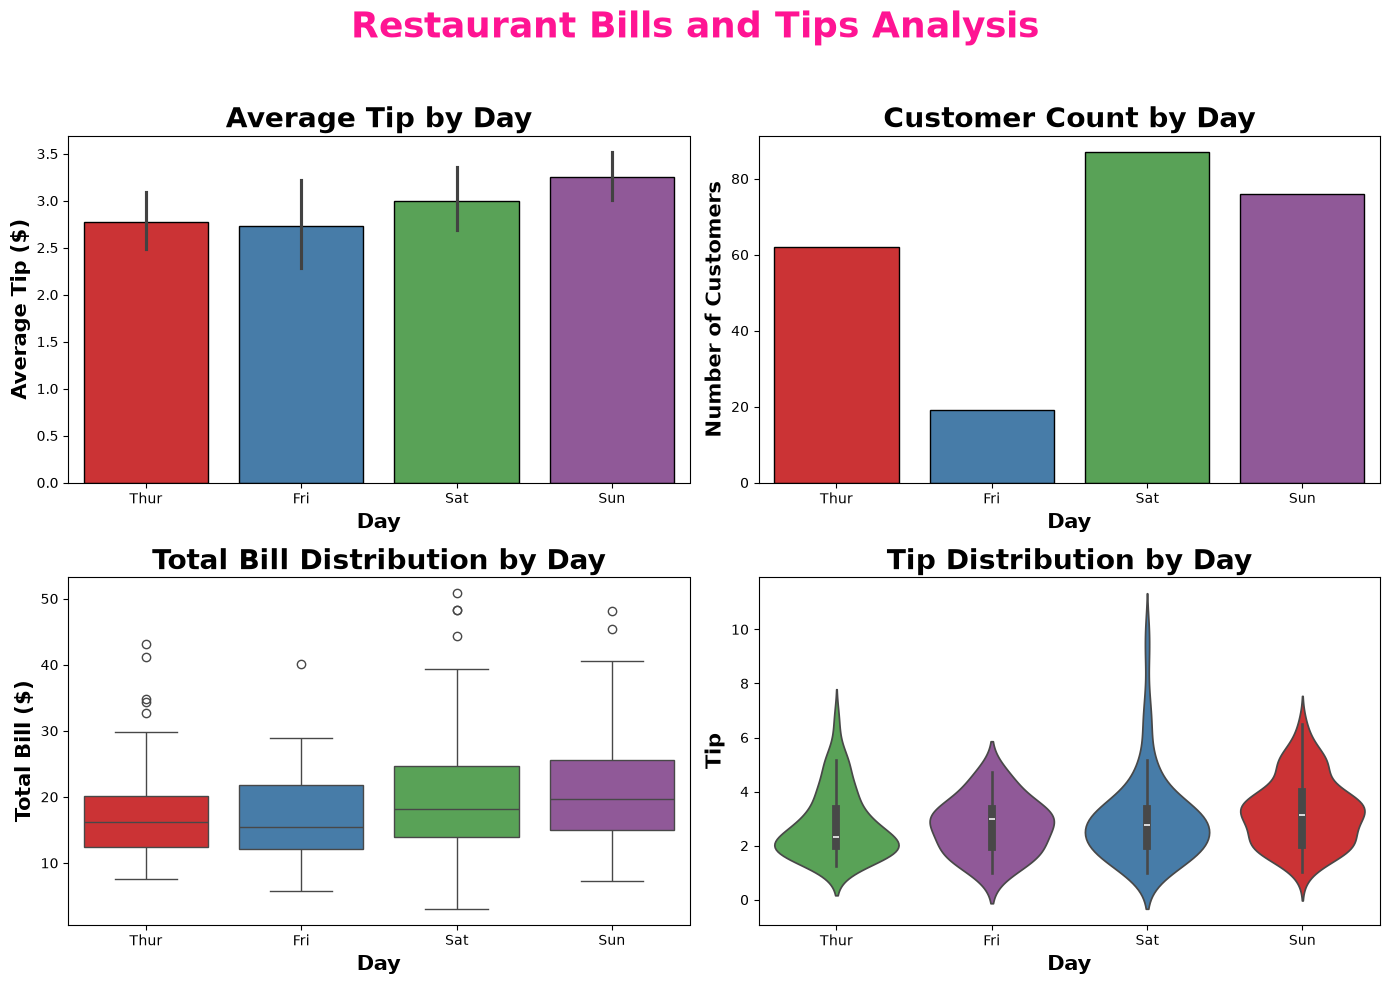

In [98]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

fig.suptitle(
    "Restaurant Bills and Tips Analysis",
    fontsize=26,
    fontweight="bold",
    color="deeppink"
)

sns.barplot(
    data=df,
    x="day",
    y="tip",
    hue="day",
    palette="Set1",
    dodge=False,
    edgecolor="black",
    legend=False,
    ax=axes[0, 0]
)

axes[0, 0].set_title(
    "Average Tip by Day",
    fontsize=20,
    fontweight="bold"
)
axes[0, 0].set_xlabel(
    "Day",
    fontsize=15,
    fontweight="bold"
)
axes[0, 0].set_ylabel(
    "Average Tip ($)",
    fontsize=15,
    fontweight="bold"
)

sns.countplot(
    data=df,
    x="day",
    hue="day",
    palette="Set1",
    dodge=False,
    edgecolor="black",
    legend=False,
    ax=axes[0, 1]
)

axes[0, 1].set_title(
    "Customer Count by Day",
    fontsize=20,
    fontweight="bold"
)
axes[0, 1].set_xlabel(
    "Day",
    fontsize=15,
    fontweight="bold"
)
axes[0, 1].set_ylabel(
    "Number of Customers",
    fontsize=15,
    fontweight="bold"
)

sns.boxplot(
    data=df,
    x="day",
    y="total_bill",
    hue="day",
    palette="Set1",
    dodge=False,
    legend=False,
    ax=axes[1, 0]
)

axes[1, 0].set_title(
    "Total Bill Distribution by Day",
    fontsize=20,
    fontweight="bold"
)
axes[1, 0].set_xlabel(
    "Day",
    fontsize=15,
    fontweight="bold"
)
axes[1, 0].set_ylabel(
    "Total Bill ($)",
    fontsize=15,
    fontweight="bold"
)

sns.violinplot(
    data=df,
    x="day",
    y="tip",
    hue="day",
    palette="Set1",
    dodge=False,
    legend=False,
    ax=axes[1, 1]
)

axes[1, 1].set_title(
    "Tip Distribution by Day",
    fontsize=20,
    fontweight="bold"
)
axes[1, 1].set_xlabel(
    "Day",
    fontsize=15,
    fontweight="bold"
)
axes[1, 1].set_ylabel(
    "Tip",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.show()

**Important:**
If you use palette without using hue it will give an error.

**Why does the error occur?**\
Suppose you write:
```python
sns.barplot(
	data=df,
	x="day",
	y="tip",
	palette="Set1"
)
```
Seaborn expects `palette` to define colors for different levels of a variable. In Seaborn `0.13+`, using `palette` without `hue` is deprecated for categorical plots and may produce a warning or an error depending on the function and environment.

The recommended approach is to specify hue.

**Solution**\
This is the approach you're already using:
```python
sns.barplot(
	data=df,
	x="day",
	y="tip",
	hue="day",
	palette="Set1",
	dodge=False,
	legend=False
)
```
Here's what each parameter does:
- `hue="day"` maps each day to a color.
- `palette="Set1"` chooses the colors.
- `dodge=False` prevents the bars from being separated into side-by-side groups.
- `legend=False` hides the redundant legend.

When you use `hue` in seaborn, it assumes you are plotting grouped data, so it automatically splits and shifts the bars horizontally to make room for each hue group. `dodge=False` fix that.